In [1]:
!pip install pandas scikit-learn matplotlib seaborn -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

In [2]:
#2. Create Workforce Dataset
np.random.seed(42)

df = pd.DataFrame({
    "Age": np.random.randint(21,60,500),
    "Department": np.random.choice(["IT","HR","Finance","Sales"],500),
    "Salary": np.random.randint(25000,120000,500),
    "Experience": np.random.randint(0,15,500),
    "Satisfaction": np.random.randint(1,11,500),
    "Performance": np.random.randint(1,11,500),
    "Engagement": np.random.randint(1,11,500),
    "Training_Hours": np.random.randint(0,100,500),
    "Attrition": np.random.choice(["Yes","No"],500)
})

df.head()

,Age,Department,Salary,Experience,Satisfaction,Performance,Engagement,Training_Hours,Attrition
0,59,IT,38046,6,1,6,6,36,Yes
1,49,IT,49818,8,4,3,10,84,No
2,35,HR,29324,2,10,7,3,7,Yes
3,28,HR,101323,7,6,4,3,27,No
4,41,Finance,34111,1,7,9,1,4,No


In [3]:
#3. Basic Workforce Analytics
print("Total Employees:", len(df))
print("Average Salary:", round(df.Salary.mean(),2))
print("Average Performance:", round(df.Performance.mean(),2))
print("Attrition Rate:", round((df.Attrition=="Yes").mean()*100,2), "%")

Total Employees: 500
Average Salary: 71122.61
Average Performance: 5.5
Attrition Rate: 53.0 %


Department
IT         141
HR         134
Finance    121
Sales      104
Name: count, dtype: int64


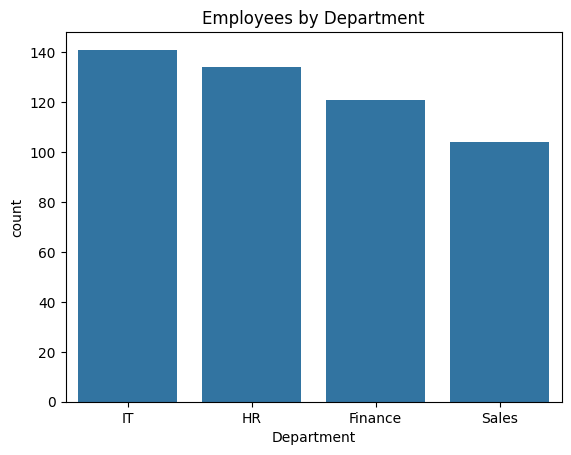

In [4]:
#4. Department Analysis
print(df["Department"].value_counts())

sns.countplot(data=df, x="Department")
plt.title("Employees by Department")
plt.show()

Department
Finance    5.115702
HR         5.619403
IT         5.127660
Sales      5.557692
Name: Engagement, dtype: float64


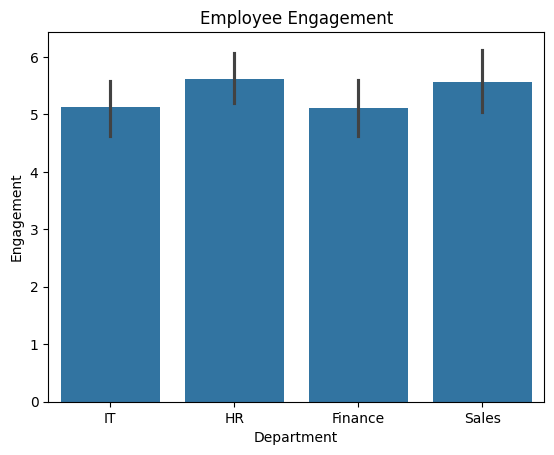

In [5]:
#5. Employee Engagement
print(df.groupby("Department")["Engagement"].mean())

sns.barplot(data=df, x="Department", y="Engagement")
plt.title("Employee Engagement")
plt.show()

In [6]:
#6. Attrition Prediction – Random Forest
data = pd.get_dummies(df, columns=["Department"])
data["Attrition"] = data["Attrition"].map({"No":0,"Yes":1})

X = data.drop("Attrition", axis=1)
y = data["Attrition"]

X_train,X_test,y_train,y_test = train_test_split(
    X,y,test_size=.2,random_state=42
)

model = RandomForestClassifier(n_estimators=100,random_state=42)
model.fit(X_train,y_train)

pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test,pred)*100,2), "%")

Accuracy: 55.0 %


In [7]:
#7. Find High-Risk Employees
df["Attrition_Risk"] = model.predict_proba(X)[:,1]*100

high_risk = df[df["Attrition_Risk"] > 70]

print(high_risk[[
    "Department","Satisfaction",
    "Engagement","Attrition_Risk"
]].head(10))

   Department  Satisfaction  Engagement  Attrition_Risk
5          HR             2           7            86.0
8          IT            10          10            90.0
12    Finance            10           8            87.0
14         HR             1           5            85.0
17         IT             6           9            85.0
22         IT             9           2            80.0
25         HR             8           3            84.0
35         IT             3           9            88.0
36         IT             9           2            82.0
37         HR            10           3            84.0


In [8]:
#8. Feature Importance
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importance.head(10))

Salary              0.187745
Training_Hours      0.162158
Age                 0.138694
Experience          0.126214
Satisfaction        0.110813
Engagement          0.101115
Performance         0.095306
Department_HR       0.020886
Department_Sales    0.020216
Department_IT       0.020016
dtype: float64


In [9]:
#9. Organizational Health Score
df["Health_Score"] = (
    df["Satisfaction"] +
    df["Performance"] +
    df["Engagement"]
) / 3

print(df[["Department","Health_Score"]].head())

  Department  Health_Score
0         IT      4.333333
1         IT      5.666667
2         HR      6.666667
3         HR      4.333333
4    Finance      5.666667


In [10]:
#10. Simple Natural Language Query
def query(q):
    q=q.lower()

    if "employees" in q:
        return len(df)
    if "salary" in q:
        return round(df.Salary.mean(),2)
    if "attrition" in q:
        return round((df.Attrition=="Yes").mean()*100,2)
    if "performance" in q:
        return round(df.Performance.mean(),2)

    return "Question not supported"

print(query("What is the attrition rate?"))

53.0
